# 01 — Exploratory Data Analysis: SEM / Irish Test System

**Dissertation: ML-accelerated Unit Commitment (AI-UC, EPRI competition benchmark)**

This notebook profiles every CSV extracted from the public SEM PLEXOS Validation model (`8_300_R08`) and the associated demand / renewable / loss-factor time series. It is deliberately *descriptive* — the goal is to know exactly what each file contains, its shape, coverage, missingness, and the few statistics that matter for building a UC environment.

**Files covered (two groups):**

*System definition (parsed from PLEXOS XML):*
- `plexos_object_inventory.csv` — count of every object class in the model
- `plexos_generators.csv` — 86 generator objects
- `plexos_batteries.csv` — 15 battery objects
- `plexos_generator_fuel_links.csv` — which fuel feeds which generator
- `plexos_generator_params_wide.csv` — one row per generator, technical UC parameters
- `plexos_values_tidy.csv` — long/tidy table of every property value in the model

*Time series (hourly, Year/Month/Day/Period grid):*
- `AI_Demand_2018-2030_5base_years.csv` — all-island demand, 5 weather base years
- `ROI_Wind`, `NI_Wind`, `Offshore_Wind` (5 base years each)
- `ROI_Solar`, `NI_Solar`, `NI_Small_Scale_Wind` (single profile)
- `202122_TLAFs.csv` — transmission loss adjustment factors per unit

> **How to run:** set `DATA_DIR` in the next cell to the folder holding the CSVs, then *Run All*.

## 0. Setup

In [30]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True

# --- EDIT THIS to point at the folder with the CSVs ---
DATA_DIR = Path('./dataset')   # e.g. Path('D:/UK/grads/Term 3 - Dissertation/data')

assert DATA_DIR.exists(), f'DATA_DIR not found: {DATA_DIR.resolve()}'
csvs = sorted(p.name for p in DATA_DIR.glob('*.csv'))
print(f'Found {len(csvs)} CSV files in {DATA_DIR.resolve()}:')
for c in csvs:
    print('  ', c)

Found 15 CSV files in D:\UK\grads\Term 3 - Dissertation\dataset:
   202122_TLAFs.csv
   AI Demand_2018-2030_5base years.csv
   NI Small Scale Wind.csv
   NI Solar.csv
   NI Wind_5base years - 2018-2030.csv
   Offshore Wind_5base years 2018-2030.csv
   ROI Solar.csv
   ROI Wind_5base years - 2018-2030.csv
   plexos_batteries.csv
   plexos_generator_fuel_links.csv
   plexos_generator_params_wide.csv
   plexos_generators.csv
   plexos_object_inventory.csv
   plexos_values_tidy.csv
   unit_names.csv


In [55]:
def quick_profile(path):
    """Load a CSV and print a compact profile: shape, dtypes, missing %, head."""
    df = pd.read_csv(path)
    print(f'=== {Path(path).name} ===')
    print(f'shape: {df.shape[0]:,} rows x {df.shape[1]} cols')
    miss = df.isna().mean().mul(100).round(1).sort_values(ascending=False)
    miss = miss[miss > 0]
    if len(miss):
        print('missing % (cols with any NaN):')
        print(miss.to_string())
    else:
        print('missing: none')
    display(df.head(3))
    return df

## 1. System definition files

### 1.1 Object inventory — what is in the model at all

=== plexos_object_inventory.csv ===
shape: 27 rows x 2 cols
missing: none


,class,n_objects
0,Generator,86
1,Company,29
2,Fuel,20


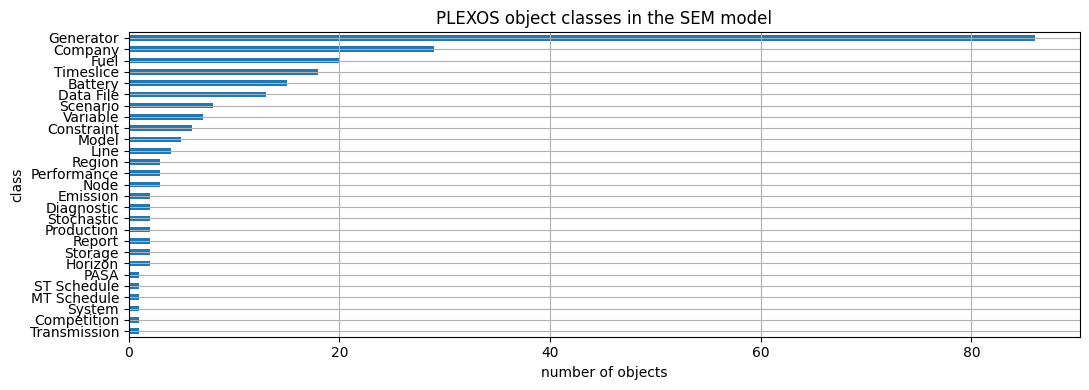

In [32]:
inv = quick_profile(DATA_DIR / 'plexos_object_inventory.csv')
inv_sorted = inv.sort_values('n_objects', ascending=True)
ax = inv_sorted.plot.barh(x='class', y='n_objects', legend=False,
                          title='PLEXOS object classes in the SEM model')
ax.set_xlabel('number of objects'); plt.tight_layout(); plt.show()

### 1.2 Generators and batteries (the fleet)

=== plexos_generators.csv ===
shape: 86 rows x 3 cols
missing: none


,object_id,name,category_id
0,2,AA1,88
1,3,AA2,88
2,4,AA3,88


=== plexos_batteries.csv ===
shape: 15 rows x 3 cols
missing: none


,object_id,name,category_id
0,424,DK1,13
1,425,KZ4,13
2,426,MZ1,13



86 generators, 15 batteries.
Generator category_id counts (categories group similar unit types):
category_id
84     20
88     15
91      9
93      8
90      6
94      5
89      4
85      4
87      3
86      3
92      2
96      2
121     2
97      1
120     1
95      1


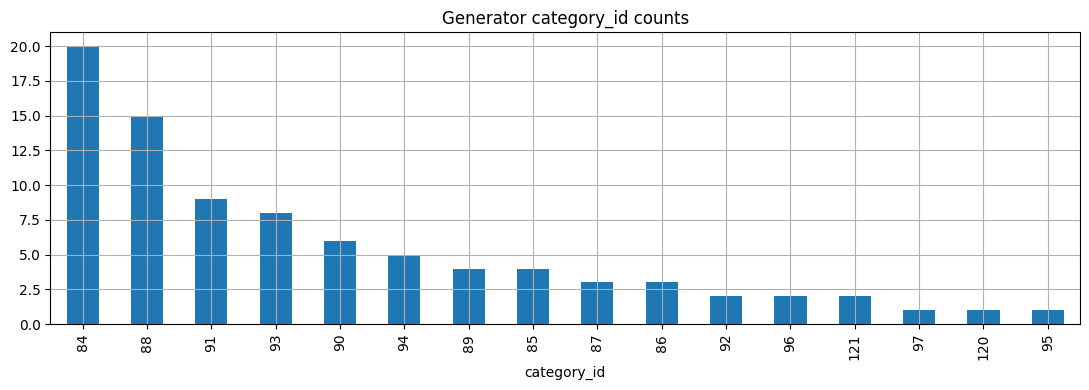

In [54]:
gens = quick_profile(DATA_DIR / 'plexos_generators.csv')
bats = quick_profile(DATA_DIR / 'plexos_batteries.csv')
print(f'\n{len(gens)} generators, {len(bats)} batteries.')
print('Generator category_id counts (categories group similar unit types):')
print(gens['category_id'].value_counts().to_string())
gens['category_id'].value_counts().plot.bar(title='Generator category_id counts')
plt.xlabel('category_id'); plt.tight_layout(); plt.show()

### 1.3 Generator–fuel links

In [34]:
fuel_links = quick_profile(DATA_DIR / 'plexos_generator_fuel_links.csv')
print('Generators per fuel (a generator may appear under multiple fuels):')
print(fuel_links['fuel'].value_counts().to_string())
print(f"\nDistinct generators with a fuel link: {fuel_links['generator'].nunique()}")
print(f"Distinct fuels: {fuel_links['fuel'].nunique()}")

=== plexos_generator_fuel_links.csv ===
shape: 126 rows x 2 cols
missing: none


,generator,fuel
0,AD1,ROI Gas w STC
1,ADC,ROI Gas
2,AT1,ROI Gas w STC


Generators per fuel (a generator may appear under multiple fuels):
fuel
ROI Gas w STC     18
NI Gas            18
ROI Distillate    18
NI Distillate     16
ROI Gas           16
ROI Oil           12
NI Coal            4
ROI Peat           4
Aughinish Gas      4
ROI Coal           4
NI Oil             3
ROI Waste          3
DB1 Gas            2
Peat ED1           1
NI Waste           1
GB Gas             1
France Gas         1

Distinct generators with a fuel link: 60
Distinct fuels: 17


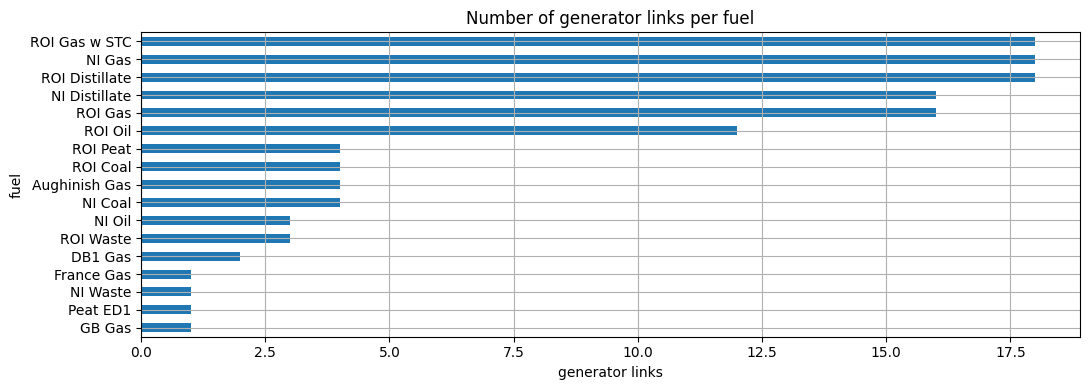

In [35]:
ax = fuel_links['fuel'].value_counts().sort_values().plot.barh(
    title='Number of generator links per fuel')
ax.set_xlabel('generator links'); plt.tight_layout(); plt.show()

### 1.4 Generator parameter table (the UC inputs)

This is the core technical table. The columns that matter most for unit commitment are: `Max Capacity`, `Min Stable Level`, `Min Up Time`, `Min Down Time`, `Start Cost Time`, `Max Ramp Up` / `Max Ramp Down`, `Forced Outage Rate`, `Heat Rate`.

In [56]:
params = quick_profile(DATA_DIR / 'plexos_generator_params_wide.csv')

uc_cols = ['Max Capacity', 'Min Stable Level', 'Min Up Time', 'Min Down Time',
           'Start Cost Time', 'Max Ramp Up', 'Max Ramp Down',
           'Forced Outage Rate', 'Heat Rate']
uc_cols = [c for c in uc_cols if c in params.columns]

print('Coverage of UC-critical parameters (how many of the 86 units have a value):')
cover = params[uc_cols].notna().sum().sort_values(ascending=False)
cover_pct = (cover / len(params) * 100).round(0)
summary = pd.DataFrame({'n_units_with_value': cover, 'pct': cover_pct})
display(summary)

=== plexos_generator_params_wide.csv ===
shape: 86 rows x 28 cols
missing % (cols with any NaN):
Heat Rate                         97.7
Hours of Operation Coefficient    97.7
Pump Units                        95.3
Pump Load                         95.3
Pump Efficiency                   95.3
Maintenance Rate                  94.2
Rating Factor                     90.7
Rating                            88.4
Outage Rating                     87.2
Generation Coefficient            82.6
Start Cost Time                   57.0
Min Up Time                       45.3
Min Down Time                     38.4
Heat Rate Incr                    34.9
Max Heat Rate Tranches            34.9
Load Point                        34.9
Heat Rate Base                    34.9
Min Stable Level                  33.7
Units Out                         26.7
Max Ramp Down                     18.6
Max Ramp Up                       18.6
Mean Time to Repair               10.5
Forced Outage Rate                10.5
Margin

,child_obj,Forced Outage Rate,Generation Coefficient,Heat Rate,Heat Rate Base,Heat Rate Incr,Hours of Operation Coefficient,Load Point,Maintenance Rate,Marginal Loss Factor,Max Capacity,Max Heat Rate Tranches,Max Ramp Down,Max Ramp Up,Mean Time to Repair,Min Down Time,Min Stable Level,Min Up Time,Offer Quantity Format,Outage Rating,Pump Efficiency,Pump Load,Pump Units,Rating,Rating Factor,Start Cost Time,Units,Units Out
0,AA1,4.1,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,21.0,NaN,0.42,0.42,86.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0
1,AA2,4.1,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,22.0,NaN,0.47,0.47,86.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0
2,AA3,4.1,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,19.0,NaN,0.33,0.33,86.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0


Coverage of UC-critical parameters (how many of the 86 units have a value):


,n_units_with_value,pct
Max Capacity,86,100.0
Forced Outage Rate,77,90.0
Max Ramp Up,70,81.0
Max Ramp Down,70,81.0
Min Stable Level,57,66.0
Min Down Time,53,62.0
Min Up Time,47,55.0
Start Cost Time,37,43.0
Heat Rate,2,2.0


In [37]:
print('Descriptive statistics for UC-critical numeric parameters:')
display(params[uc_cols].describe().T.round(2))

Descriptive statistics for UC-critical numeric parameters:


,count,mean,std,min,25%,50%,75%,max
Max Capacity,86.0,230.88,548.23,0.00,29.00,73.00,242.50,4000.00
Min Stable Level,57.0,55.89,54.64,1.00,12.82,34.85,99.00,211.00
Min Up Time,47.0,2.35,1.95,0.02,0.50,2.00,4.00,6.00
Min Down Time,53.0,2.34,2.06,0.02,0.50,1.00,4.00,10.00
Start Cost Time,37.0,10.99,3.70,0.50,10.00,12.00,12.00,24.00
Max Ramp Up,70.0,7.18,8.30,0.03,1.66,5.00,10.00,50.00
Max Ramp Down,70.0,8.60,8.81,0.04,2.20,5.91,10.00,50.00
Forced Outage Rate,77.0,6.56,5.21,3.40,4.10,5.50,5.50,23.40
Heat Rate,2.0,5.15,1.16,4.33,4.74,5.15,5.56,5.97


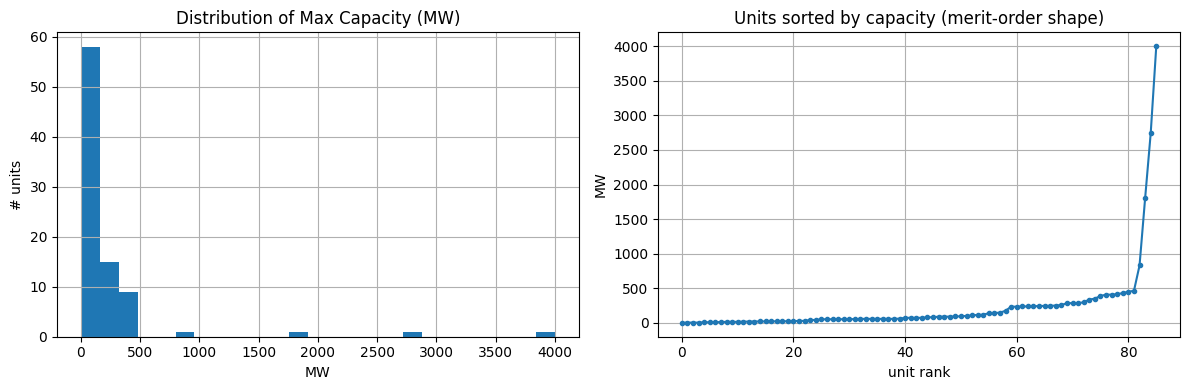

Total installed thermal/hydro capacity: 19,855 MW across 86 units


In [38]:
# Distribution of installed capacity across the fleet
cap = params['Max Capacity'].dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(cap, bins=25)
ax[0].set_title('Distribution of Max Capacity (MW)')
ax[0].set_xlabel('MW'); ax[0].set_ylabel('# units')
cap.sort_values().reset_index(drop=True).plot(ax=ax[1], marker='.')
ax[1].set_title('Units sorted by capacity (merit-order shape)')
ax[1].set_xlabel('unit rank'); ax[1].set_ylabel('MW')
plt.tight_layout(); plt.show()
print(f'Total installed thermal/hydro capacity: {cap.sum():,.0f} MW across {len(cap)} units')

### 1.5 The tidy value table — every property in the model

`plexos_values_tidy.csv` is the long-format master. Useful to (a) see which properties exist and how often, and (b) **confirm whether any solved/output quantities exist** (a key scoping question for the dissertation).

In [39]:
tidy = pd.read_csv(DATA_DIR / 'plexos_values_tidy.csv')
print(f'tidy table: {tidy.shape[0]:,} rows x {tidy.shape[1]} cols')
print('\nTop 25 properties by frequency:')
print(tidy['property'].value_counts().head(25).to_string())

tidy table: 29,231 rows x 16 cols

Top 25 properties by frequency:
property
Wheeling Charge Back      10368
Wheeling Charge           10368
Units Out                  3076
Price                      1148
Holiday                     910
Max Capacity                602
Outage Rating               260
Offtake at Start            219
Heat Rate                   192
Heat Rate Incr              146
Load Point                  146
Units                       145
Start Cost Time             110
Shadow Price                104
Forced Outage Rate           96
Mean Time to Repair          96
Marginal Loss Factor         92
Offer Quantity Format        88
Max Ramp Down                85
Max Ramp Up                  85
Maximum                      70
Energy                       70
Min Stable Level             57
Max Heat Rate Tranches       56
Heat Rate Base               56


In [40]:
print('Rows per child_class (which object types carry values):')
print(tidy['child_class'].value_counts().to_string())

# Scoping check: is there any solved dispatch / commitment output in the model?
solved_like = tidy[tidy['property'].str.contains(
    'Dispatch|Commit|Unit Start|Flow Result|Generation Output', case=False, na=False)]
print(f'\nRows that look like SOLVED output (dispatch/commitment): {len(solved_like)}')
if solved_like.empty:
    print('--> No solved benchmark in the model. Ground-truth UC solutions must be')
    print('    generated by a MILP solver (this is what notebook 02 does).')

Rows per child_class (which object types carry values):
child_class
Line          21062
Generator      5266
Fuel           1279
Data File      1068
Battery         216
Emission        208
Constraint       56
Region           31
Timeslice        18
Variable         16
Storage           6
Node              5

Rows that look like SOLVED output (dispatch/commitment): 0
--> No solved benchmark in the model. Ground-truth UC solutions must be
    generated by a MILP solver (this is what notebook 02 does).


In [41]:
# What 'Price' means here: input fuel/emission price, not a market-clearing output
price = tidy[tidy['property'] == 'Price']
print('"Price" rows by (child_class, collection):')
print(price.groupby(['child_class', 'collection']).size().to_string())

"Price" rows by (child_class, collection):
child_class  collection
Emission     Emissions      104
Fuel         Fuels         1044


## 2. Time-series files (demand & renewables)

All share the `Year, Month, Day, Period` index. `Period` runs 1–24 (hourly). Demand and the three main wind/offshore files plus demand carry **5 base-year (weather) columns**; solar and small-scale wind carry a single profile column.

In [42]:
TS_FILES = {
    'demand'        : 'AI Demand_2018-2030_5base years.csv',
    'roi_wind'      : 'ROI Wind_5base years - 2018-2030.csv',
    'ni_wind'       : 'NI Wind_5base years - 2018-2030.csv',
    'offshore_wind' : 'Offshore Wind_5base years 2018-2030.csv',
    'roi_solar'     : 'ROI Solar.csv',
    'ni_solar'      : 'NI Solar.csv',
    'ni_ss_wind'    : 'NI Small Scale Wind.csv',
}

INDEX = ['Year', 'Month', 'Day', 'Period']

def load_ts(fname):
    df = pd.read_csv(DATA_DIR / fname)
    value_cols = [c for c in df.columns if c not in INDEX]
    return df, value_cols

ts = {}
for key, fname in TS_FILES.items():
    df, vcols = load_ts(fname)
    ts[key] = (df, vcols)
    yr0, yr1 = int(df['Year'].min()), int(df['Year'].max())
    print(f'{key:14s} {df.shape[0]:>7,} rows | base-year cols: {vcols} | years {yr0}-{yr1} '
          f'| periods {int(df.Period.min())}-{int(df.Period.max())}')

demand         113,952 rows | base-year cols: ['1', '2', '3', '4', '5'] | years 2018-2030 | periods 1-24
roi_wind       113,952 rows | base-year cols: ['1', '2', '3', '4', '5'] | years 2018-2030 | periods 1-24
ni_wind        113,952 rows | base-year cols: ['1', '2', '3', '4', '5'] | years 2018-2030 | periods 1-24
offshore_wind  113,952 rows | base-year cols: ['1', '2', '3', '4', '5'] | years 2018-2030 | periods 1-24
roi_solar       96,432 rows | base-year cols: ['1'] | years 2020-2030 | periods 1-24
ni_solar        96,432 rows | base-year cols: ['1'] | years 2020-2030 | periods 1-24
ni_ss_wind      96,432 rows | base-year cols: ['1'] | years 2020-2030 | periods 1-24


In [43]:
def add_datetime(df):
    """Build a proper timestamp from Y/M/D + hourly Period (1->00:00)."""
    d = df.copy()
    d['dt'] = pd.to_datetime(dict(year=d.Year, month=d.Month, day=d.Day)) \
              + pd.to_timedelta(d['Period'] - 1, unit='h')
    return d

# Demand: statistics across the 5 base years
dem, dem_cols = ts['demand']
print('All-island demand (MW) — describe across 5 base years:')
display(dem[dem_cols].describe().T.round(0))

All-island demand (MW) — describe across 5 base years:


,count,mean,std,min,25%,50%,75%,max
1,113952.0,5014.0,1043.0,2535.0,4198.0,5039.0,5810.0,8270.0
2,113952.0,5014.0,974.0,2641.0,4263.0,5057.0,5762.0,8270.0
3,113952.0,5014.0,1015.0,2576.0,4230.0,5057.0,5789.0,8270.0
4,113952.0,5014.0,997.0,2555.0,4244.0,5062.0,5777.0,8270.0
5,113952.0,5014.0,1023.0,2480.0,4217.0,5071.0,5801.0,8270.0


In [44]:
rows = []

for key, (df, vcols) in ts.items():
    d = add_datetime(df)

    # duplicate timestamp check
    dup_ts = d.duplicated(['Year', 'Month', 'Day', 'Period']).sum()

    # how many periods per day? should be 24
    per_day = d.groupby(['Year', 'Month', 'Day'])['Period'].nunique()
    bad_days = int((per_day != 24).sum())
    missing_periods = int((24 - per_day).clip(lower=0).sum())

    # basic value checks
    vals = df[vcols].values
    neg = int((vals < 0).sum())

    rows.append({
        'file': key,
        'rows': len(df),
        'duplicate_timestamps': int(dup_ts),
        'days_with_bad_period_count': bad_days,
        'missing_periods_est': missing_periods,
        'n_negative_values': neg,
        'min': float(np.nanmin(vals)),
        'max': float(np.nanmax(vals)),
        'any_nan': bool(df[vcols].isna().any().any()),
    })

qc = pd.DataFrame(rows).set_index('file')
display(qc)

print('Files with duplicate timestamps:', qc.index[qc['duplicate_timestamps'] > 0].tolist())
print('Files with days missing periods:', qc.index[qc['days_with_bad_period_count'] > 0].tolist())
print('Files with negative values:', qc.index[qc['n_negative_values'] > 0].tolist())

,rows,duplicate_timestamps,days_with_bad_period_count,missing_periods_est,n_negative_values,min,max,any_nan
file,,,,,,,,
demand,113952,0,0,0,0,2480.000,8270.000000,False
roi_wind,113952,0,0,0,0,0.000,92.219515,False
ni_wind,113952,0,0,0,0,0.000,96.922341,False
offshore_wind,113952,0,0,0,0,0.000,100.000000,False
roi_solar,96432,0,0,0,0,0.000,54.184000,False
ni_solar,96432,0,0,0,0,0.000,55.894000,False
ni_ss_wind,96432,0,0,0,0,0.026,69.133000,False


Files with duplicate timestamps: []
Files with days missing periods: []
Files with negative values: []


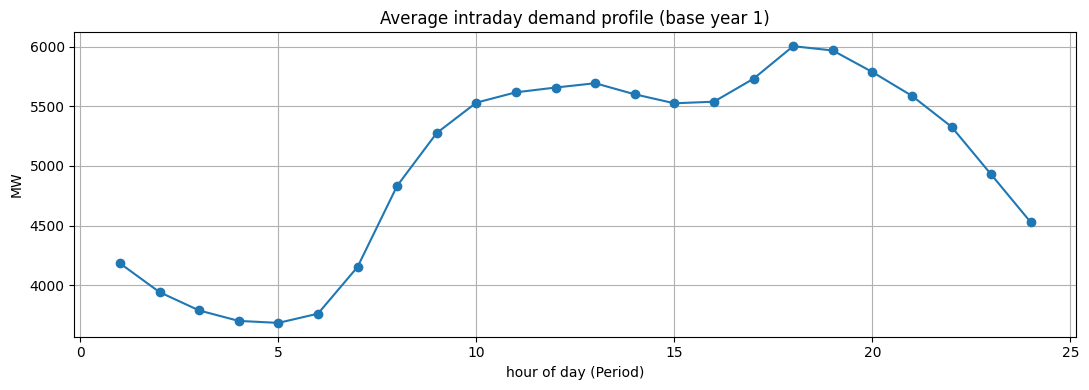

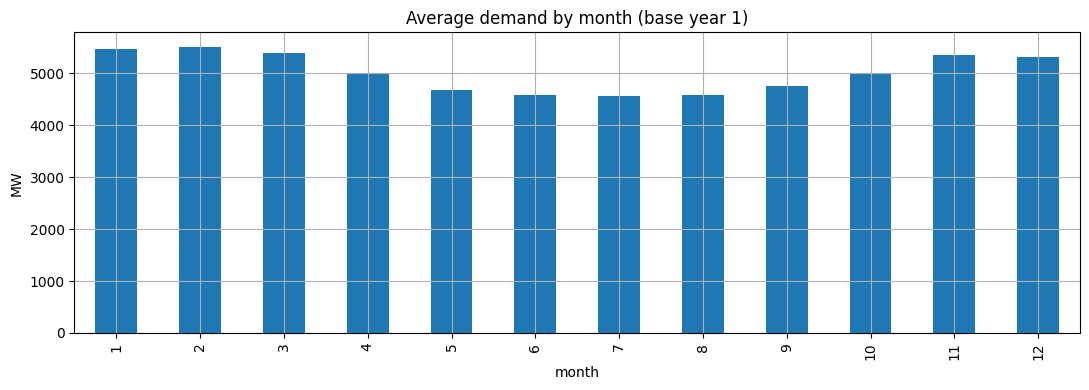

In [45]:
# Average daily demand shape (mean over all days), base year '1'
dem_dt = add_datetime(dem)
daily_shape = dem_dt.groupby('Period')['1'].mean()
ax = daily_shape.plot(marker='o', title='Average intraday demand profile (base year 1)')
ax.set_xlabel('hour of day (Period)'); ax.set_ylabel('MW'); plt.tight_layout(); plt.show()

# Monthly (seasonal) average demand
monthly = dem_dt.groupby('Month')['1'].mean()
ax = monthly.plot.bar(title='Average demand by month (base year 1)')
ax.set_xlabel('month'); ax.set_ylabel('MW'); plt.tight_layout(); plt.show()

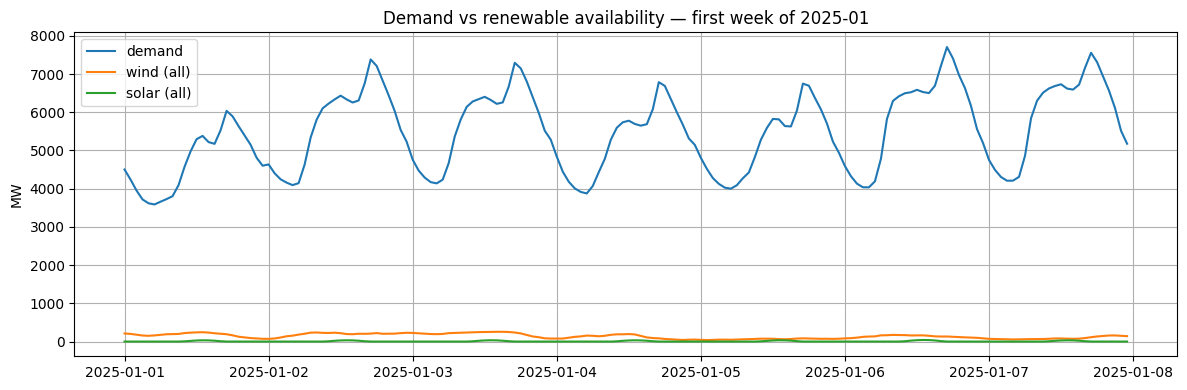

In [46]:
# One representative week of demand vs total renewable availability (base year 1)
def series_for_year1(key):
    df, vcols = ts[key]
    col = '1' if '1' in df.columns else vcols[0]
    return add_datetime(df).set_index('dt')[col]

year, month = 2025, 1
mask = lambda s: (s.index.year == year) & (s.index.month == month)

d = series_for_year1('demand')
wind_total = (series_for_year1('roi_wind') + series_for_year1('ni_wind')
              + series_for_year1('offshore_wind'))
solar_total = series_for_year1('roi_solar') + series_for_year1('ni_solar')

window = slice(f'{year}-{month:02d}-01', f'{year}-{month:02d}-07 23:00')
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(d[window].index, d[window].values, label='demand')
ax.plot(wind_total[window].index, wind_total[window].values, label='wind (all)')
ax.plot(solar_total[window].index, solar_total[window].values, label='solar (all)')
ax.set_title(f'Demand vs renewable availability — first week of {year}-{month:02d}')
ax.set_ylabel('MW'); ax.legend(); plt.tight_layout(); plt.show()

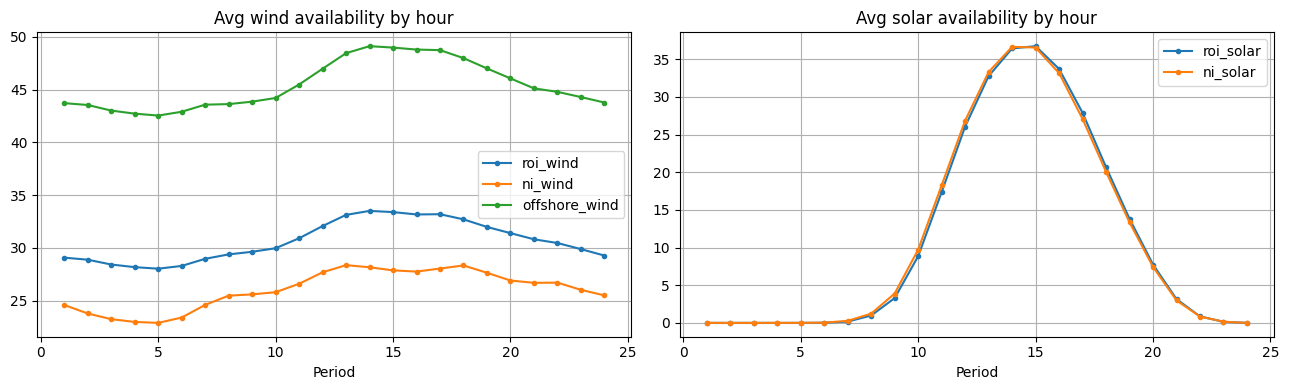

In [47]:
# Renewable capacity-factor-style summary: average availability per hour of day
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for key in ['roi_wind', 'ni_wind', 'offshore_wind']:
    df, vcols = ts[key]
    s = add_datetime(df).groupby('Period')['1'].mean()
    ax[0].plot(s.index, s.values, marker='.', label=key)
ax[0].set_title('Avg wind availability by hour'); ax[0].set_xlabel('Period'); ax[0].legend()
for key in ['roi_solar', 'ni_solar']:
    df, vcols = ts[key]
    s = add_datetime(df).groupby('Period')[vcols[0]].mean()
    ax[1].plot(s.index, s.values, marker='.', label=key)
ax[1].set_title('Avg solar availability by hour'); ax[1].set_xlabel('Period'); ax[1].legend()
plt.tight_layout(); plt.show()

### 2.1 TLAFs — transmission loss adjustment factors

=== 202122_TLAFs.csv ===
shape: 1,752 rows x 3 cols
missing: none


,Name,Pattern,Value
0,AA1,"M01, H1-7, H23-24",0.95
1,AA2,"M01, H1-7, H23-24",0.95
2,AA3,"M01, H1-7, H23-24",0.95


TLAF value distribution:


count    1752.0000
mean        0.9792
std         0.0122
min         0.9370
25%         0.9720
50%         0.9800
75%         0.9900
max         1.0010
Name: Value, dtype: float64

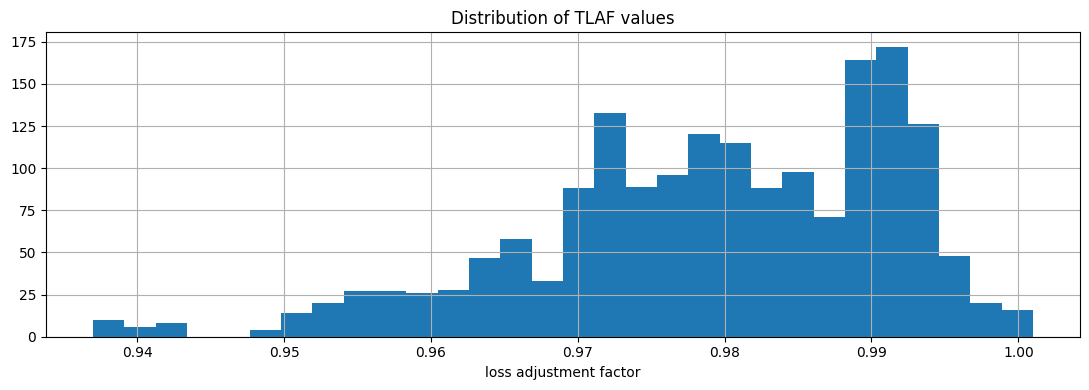

Distinct units with a TLAF: 73


In [48]:
tlaf = quick_profile(DATA_DIR / '202122_TLAFs.csv')
print('TLAF value distribution:')
display(tlaf['Value'].describe().round(4))
ax = tlaf['Value'].hist(bins=30)
ax.set_title('Distribution of TLAF values'); ax.set_xlabel('loss adjustment factor')
plt.tight_layout(); plt.show()
print(f"Distinct units with a TLAF: {tlaf['Name'].nunique()}")

## 3. Data-quality checks across time series

Confirm there are no gaps in the hourly grid and flag negatives / out-of-range values before the data is used to build a UC environment.

## 4. EDA summary

Use these points as the handoff into notebook 02 and the dissertation write-up:

- **Fleet structure:** the SEM model contains 86 generators and 15 batteries in the object inventory. The generator-capacity plot shows a clear merit-order shape, so selecting a smaller UC subset later is reasonable for a demo, but the full set is available in the source data.
- **UC input coverage:** the core UC parameters are not complete for every unit. In particular, `Max Capacity`, `Min Stable Level`, `Min Up Time`, `Min Down Time`, ramp limits, heat rate, and start-cost proxies are only partially populated. That means some units will need defaults, while others may be better treated as must-run / non-dispatchable assets.
- **Cost data:** the tidy value table confirms that `Price` entries are input prices, not market-clearing outputs. For UC modelling, marginal cost should be built from fuel price plus heat rate (and optionally VOM / emissions if you want).
- **Time series:** demand, wind, and solar are hourly series with `Period = 1..24`. The representative-week plots show the right overall shape: demand varies strongly by hour and season, wind is more volatile, and solar is strongly diurnal.
- **Feasibility check:** the hourly demand plus renewable summary is enough to build a 72-hour episode for RL / UC. The next notebook should define the episode start date, net demand, and the subset of generators used for the solver and the RL environment.
- **Data quality:** the grid checks should be read together with the summary table above. Before modelling, confirm there are no duplicate timestamps, no missing hourly periods, and no unexpected negative values in files that should be strictly non-negative.

In short: the EDA is sufficient to move on, but the UC notebook still needs one consistent definition of the instance (same units, same horizon, same cost logic) so the RL, MILP, and visualisation steps all compare the same problem.


# 4. UC-Ready Unit Coverage

In [52]:
# UC-ready coverage: which units have the core UC fields?
uc_need = ['Max Capacity', 'Min Stable Level', 'Min Up Time', 'Min Down Time',
           'Max Ramp Up', 'Max Ramp Down', 'Heat Rate', 'Start Cost Time']

present = [c for c in uc_need if c in params.columns]

# Units with the minimum fields needed for UC
uc_ready = params.dropna(subset=['Max Capacity', 'Min Stable Level', 'Min Up Time', 'Min Down Time']).copy()

print(f'UC-ready units: {len(uc_ready)} / {len(params)}')

# Missingness by column
missing = params[present].isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(params) * 100).round(1)
missing_df = pd.DataFrame({
    'missing_count': missing,
    'missing_pct': missing_pct
})
display(missing_df)

print('\nTop UC-ready units by capacity:')
cols_to_show = [c for c in ['Max Capacity', 'Min Stable Level', 'Min Up Time', 'Min Down Time',
                            'Max Ramp Up', 'Max Ramp Down', 'Heat Rate', 'Start Cost Time']
                if c in uc_ready.columns]
display(
    uc_ready[cols_to_show]
    .sort_values('Max Capacity', ascending=False)
    .head(50)
)

UC-ready units: 46 / 86


,missing_count,missing_pct
Heat Rate,84,97.7
Start Cost Time,49,57.0
Min Up Time,39,45.3
Min Down Time,33,38.4
Min Stable Level,29,33.7
Max Ramp Down,16,18.6
Max Ramp Up,16,18.6
Max Capacity,0,0.0



Top UC-ready units by capacity:


,Max Capacity,Min Stable Level,Min Up Time,Min Down Time,Max Ramp Up,Max Ramp Down,Heat Rate,Start Cost Time
32,464.000,165.00,4.00,4.00,17.170,18.500,NaN,12.0
78,450.000,160.00,4.00,4.00,23.320,26.800,NaN,12.0
5,431.000,120.00,4.00,4.00,8.830,12.380,NaN,12.0
19,415.000,110.00,4.00,4.00,10.000,4.480,NaN,12.0
34,408.000,121.00,4.00,4.00,20.000,20.000,NaN,12.0
17,408.000,211.00,4.00,4.00,15.000,15.000,NaN,12.0
77,389.000,194.00,4.00,4.00,15.000,12.500,NaN,12.0
43,350.000,130.00,0.02,0.02,30.800,30.800,NaN,NaN
35,337.000,120.00,4.00,4.00,7.000,7.000,NaN,12.0
44,298.000,130.00,0.02,0.02,30.800,30.800,NaN,NaN


# 5. 72-hour Episode Feasibility

Total installed capacity : 19,855 MW
Peak demand              : 8,270 MW
Peak wind + solar        : 341 MW
Peak net demand          : 8,218 MW
Hours with renewable surplus (net < 0): 0
Hours with net demand > total capacity : 0


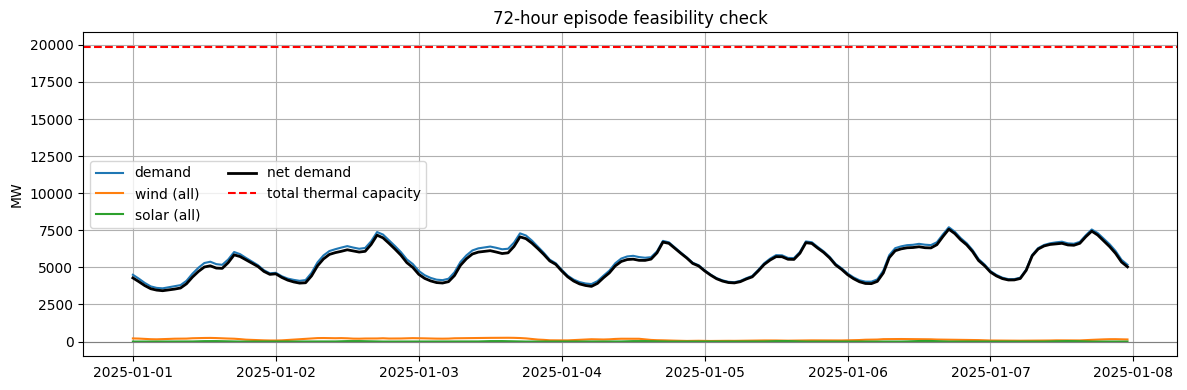

In [51]:
# 72-hour episode feasibility check
# Use the same representative week you already plotted
d = series_for_year1('demand')
wind_total = (series_for_year1('roi_wind') + series_for_year1('ni_wind') +
              series_for_year1('offshore_wind'))
solar_total = series_for_year1('roi_solar') + series_for_year1('ni_solar')
net_total = d - wind_total - solar_total

# Total thermal/hydro capacity from UC-ready fleet
thermal_capacity = params['Max Capacity'].dropna().sum()

print(f'Total installed capacity : {thermal_capacity:,.0f} MW')
print(f'Peak demand              : {d.max():,.0f} MW')
print(f'Peak wind + solar        : {(wind_total + solar_total).max():,.0f} MW')
print(f'Peak net demand          : {net_total.max():,.0f} MW')
print(f'Hours with renewable surplus (net < 0): {(net_total < 0).sum()}')
print(f'Hours with net demand > total capacity : {(net_total > thermal_capacity).sum()}')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(d[window].index, d[window].values, label='demand')
ax.plot(wind_total[window].index, wind_total[window].values, label='wind (all)')
ax.plot(solar_total[window].index, solar_total[window].values, label='solar (all)')
ax.plot(net_total[window].index, net_total[window].values, label='net demand', lw=2, color='black')
ax.axhline(thermal_capacity, color='red', ls='--', lw=1.5, label='total thermal capacity')
ax.axhline(0, color='grey', lw=0.8)

ax.set_title('72-hour episode feasibility check')
ax.set_ylabel('MW')
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

# EDA summary

- **Fleet structure**: the SEM model contains 86 generators and 15 batteries in the object inventory. The Max Capacity distribution shows a clear merit-order shape, so selecting a smaller UC subset later is reasonable for a demo, but the full set is available in the source data.
- **UC input coverage**: not all 86 units carry the full UC parameter set. In particular, `Max Capacity, Min Stable Level, Min Up Time, Min Down Time, ramp limits, heat rate, and start-cost` proxies are only partially populated. That means some units will need defaults, while others may be better treated as must-run / non-dispatchable assets.
- **Costs**: fuel links + fuel EUR/GJ prices + heat rate give marginal cost. `Price` in the tidy table is an input fuel/emission price, not a market-clearing output.
- **No solved benchmark**: the model contains no dispatch/commitment outputs → ground truth must be generated by a MILP solver in notebook 02.
- **Time series**: demand, wind, and solar are hourly series with Period = 1-24. Demand + the three wind files carry 5 weather base years; solar and small-scale wind carry one profile.
- **Feasibility check**: the hourly demand plus renewable summary is enough to build a 72-hour episode for RL / UC. <br />
The next notebook should define the episode start date, net demand, and the subset of generators used for the solver and the RL environment.
- **Data quality**: the grid checks should be read together with the summary table above. <br />
Before modelling, confirm there are no duplicate timestamps, no missing hourly periods, and no unexpected negative values in files that should be strictly non-negative.

In short: the EDA is sufficient to move on, but the UC notebook still needs one consistent definition of the instance (same units, same horizon, same cost logic) so the RL, MILP, and visualisation steps all compare the same problem.